<a href="https://colab.research.google.com/github/Shreshta1234/Fellowship-training-868661/blob/main/Shreshta_Nagaraju_4_Days_Training_assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd


yield_df = pd.read_csv('/content/yield.csv')
rainfall_df = pd.read_csv('/content/rainfall.csv')

print(yield_df.head())
print(yield_df.columns)

print(rainfall_df.head())
print(rainfall_df.columns)


  Domain Code Domain  Area Code         Area  Element Code Element  Item Code  \
0          QC  Crops          2  Afghanistan          5419   Yield         56   
1          QC  Crops          2  Afghanistan          5419   Yield         56   
2          QC  Crops          2  Afghanistan          5419   Yield         56   
3          QC  Crops          2  Afghanistan          5419   Yield         56   
4          QC  Crops          2  Afghanistan          5419   Yield         56   

    Item  Year Code  Year   Unit  Value  
0  Maize       1961  1961  hg/ha  14000  
1  Maize       1962  1962  hg/ha  14000  
2  Maize       1963  1963  hg/ha  14260  
3  Maize       1964  1964  hg/ha  14257  
4  Maize       1965  1965  hg/ha  14400  
Index(['Domain Code', 'Domain', 'Area Code', 'Area', 'Element Code', 'Element',
       'Item Code', 'Item', 'Year Code', 'Year', 'Unit', 'Value'],
      dtype='object')
          Area  Year average_rain_fall_mm_per_year
0  Afghanistan  1985                     

In [ ]:

yield_df.columns = yield_df.columns.str.strip()
rainfall_df.columns = rainfall_df.columns.str.strip()

data = pd.merge(
    yield_df,
    rainfall_df,
    on=['Area', 'Year'],
    how='inner'
)


data = data.dropna(
    subset=['average_rain_fall_mm_per_year', 'Value']
)


X = data[['average_rain_fall_mm_per_year']].to_numpy()
y = data['Value'].to_numpy()

print("Dataset shape:", data.shape)
print(data[['Area', 'Year', 'Item',
            'average_rain_fall_mm_per_year', 'Value']].head())
print("X shape:", X.shape)
print("y shape:", y.shape)

Dataset shape: (25400, 13)
          Area  Year   Item average_rain_fall_mm_per_year  Value
0  Afghanistan  1985  Maize                           327  16652
1  Afghanistan  1986  Maize                           327  16875
2  Afghanistan  1987  Maize                           327  17020
3  Afghanistan  1989  Maize                           327  16963
4  Afghanistan  1990  Maize                           327  17582
X shape: (25400, 1)
y shape: (25400,)


In [ ]:
import numpy as np
idx=np.random.default_rng(0).permutation(len(X))
cut=int(0.8*len(X)); tr,te=idx[:cut],idx[cut:]
print(y[tr].mean(), y[tr].var(), y[tr].std())

68254.87755905512 5624169583.244851 74994.46368396038


In [ ]:
import pandas as pd
import numpy as np

x = pd.to_numeric(data['average_rain_fall_mm_per_year'], errors='coerce')
y = pd.to_numeric(data['Value'], errors='coerce')

mask = x.notna() & y.notna()
x = x[mask].to_numpy(dtype=float)
y = y[mask].to_numpy(dtype=float)

print(x.dtype, y.dtype, x.shape, y.shape)

float64 float64 (25385,) (25385,)


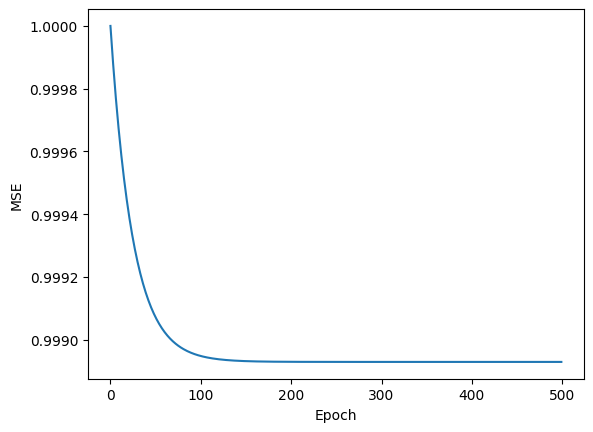

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# scale the data so the loop doesn't blow up
xs = (x - x.mean()) / x.std()
ys = (y - y.mean()) / y.std()

w = b = 0.0
lr = 0.01
losses = []

for e in range(500):
    err = w * xs + b - ys
    w -= lr * 2 * (err * xs).mean()
    b -= lr * 2 * err.mean()
    losses.append((err ** 2).mean())

plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.show()

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_auc_score

rng = np.random.default_rng(0)
X = rng.uniform([5, 15, 20], [60, 42, 90], (1000, 3))
z = -0.15*(X[:,0]-30) + 0.2*(X[:,1]-28) - 0.04*(X[:,2]-55)
y = (rng.random(1000) < 1/(1+np.exp(-z))).astype(int)


Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=0)
sc = StandardScaler().fit(Xtr)
Xtr, Xte = sc.transform(Xtr), sc.transform(Xte)


m = LogisticRegression().fit(Xtr, ytr)
print(confusion_matrix(yte, m.predict(Xte)))
print(roc_auc_score(yte, m.predict_proba(Xte)[:, 1]))

[[90 17]
 [12 81]]
0.943824741232037


In [ ]:
import numpy as np
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.preprocessing import StandardScaler


rng = np.random.default_rng(0)
X = rng.normal(size=(100, 8))
y = 3*X[:, 0] - 2*X[:, 1] + X[:, 2] + rng.normal(0, 2, 100)


Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=0)
sc = StandardScaler().fit(Xtr)
Xtr, Xte = sc.transform(Xtr), sc.transform(Xte)

gs = GridSearchCV(Ridge(), {"alpha": [0.01, 0.1, 1, 10, 100]}, cv=5).fit(Xtr, ytr)
alpha = gs.best_params_["alpha"]
print("best alpha:", alpha)


def fit(X, y, alpha, lr=0.05, epochs=2000):
    n = len(y)
    w, b = np.zeros(X.shape[1]), 0.0
    for _ in range(epochs):
        err = X @ w + b - y
        w -= lr * (2 * (X.T @ err) / n + 2 * alpha / n * w)
        b -= lr * 2 * err.mean()
    return w, b

w0, b0 = fit(Xtr, ytr, alpha=0)
w1, b1 = fit(Xtr, ytr, alpha=alpha)


mse = lambda w, b: ((Xte @ w + b - yte) ** 2).mean()
print("test MSE, no L2  :", round(mse(w0, b0), 3))
print("test MSE, with L2:", round(mse(w1, b1), 3))
print("weights no L2  :", np.round(w0, 2))
print("weights with L2:", np.round(w1, 2))

best alpha: 1
test MSE, no L2  : 3.7
test MSE, with L2: 3.741
weights no L2  : [ 2.07 -1.79  0.61 -0.35 -0.34  0.35 -0.12  0.12]
weights with L2: [ 2.05 -1.76  0.6  -0.35 -0.33  0.34 -0.11  0.12]
